In [183]:
# --------- 1 ------------
import numpy as np
import pandas as pd

from lightgbm import LGBMRegressor

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

from sklearn.model_selection import KFold

In [184]:
df = pd.read_parquet("/home/prasanna/Ishan/ACRI_Data_Prep_Analysis/final_training_ACRI_1998_2025.parquet")
df.head(3)

,latitude,longitude,Year,Month,month_sin,month_cos,zos,so,thetao,uo,vo,mlotst_ln,vorticity,okubo_weiss,grad_ssh,chlor_a_log10
0,5.083333,48.416668,1998,1,0.5,0.866025,0.356643,35.085851,27.240661,-0.214890,-0.258462,3.203022,-0.000001,-4.432381e-13,7.225481e-07,-0.591444
1,5.083333,48.500000,1998,1,0.5,0.866025,0.350835,35.190106,27.319741,-0.217311,-0.259840,3.522403,-0.000005,-4.999900e-12,6.700163e-07,-0.677223
2,5.083333,48.583332,1998,1,0.5,0.866025,0.344721,35.220427,27.334367,-0.254780,-0.304201,3.699259,-0.000006,-1.445125e-11,6.258408e-07,-0.699379


In [185]:
# ---------- 2 ------------

df = pd.read_parquet("/home/prasanna/Ishan/ACRI_Data_Prep_Analysis/final_training_ACRI_1998_2025.parquet")

# -----------------------------
# Western Arabian Sea
# Lon: 45°E–65°E
# Lat: 5°N–28°N
# -----------------------------

df = df[
    (df["longitude"] >= 45) &
    (df["longitude"] <= 65) &
    (df["latitude"]  >= 5) &
    (df["latitude"]  <= 25)
].copy()

print(f"Total samples in Western Arabian Sea = {len(df):,}")

TARGET = "chlor_a_log10"

DROP_COLS = [
    TARGET,
    "latitude",
    "longitude",
    "Year",
    "Month",
    "zos",
    "grad_ssh"
]

# -----------------------------
# Train : 1998–2023
# Test  : 2024–2025
# -----------------------------

train_df = df[
    (df["Year"] >= 1998) &
    (df["Year"] <= 2023)
].copy()

test_df = df[
    (df["Year"] >= 2024) &     # 98-24 for occci   # 98-23 for ACRI
    (df["Year"] <= 2025)       
].copy()

train_df = train_df.sort_values(
    ["Year", "Month"]
).reset_index(drop=True)

test_df = test_df.sort_values(
    ["Year", "Month"]
).reset_index(drop=True)

FEATURES = [
    col for col in df.columns
    if col not in DROP_COLS
]

X_train = train_df[FEATURES].astype("float32")
y_train = train_df[TARGET].astype("float32")

X_test = test_df[FEATURES].astype("float32")
y_test = test_df[TARGET].astype("float32")

print(f"Training samples : {len(X_train):,}")
print(f"Testing samples  : {len(X_test):,}")
print(f"Number of features : {len(FEATURES)}")


Total samples in Western Arabian Sea = 11,835,586
Training samples : 10,990,036
Testing samples  : 845,550
Number of features : 9


In [186]:
X_train.head(2)

,month_sin,month_cos,so,thetao,uo,vo,mlotst_ln,vorticity,okubo_weiss
0,0.5,0.866025,35.085850,27.240662,-0.214890,-0.258462,3.203022,-0.000001,-4.432381e-13
1,0.5,0.866025,35.190105,27.319742,-0.217311,-0.259840,3.522403,-0.000005,-4.999900e-12


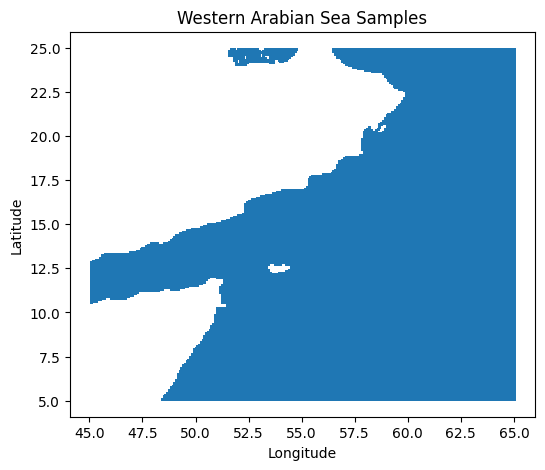

In [187]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6,5))
plt.scatter(
    df["longitude"],
    df["latitude"],
    s=0.1,
    alpha=0.2
)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Western Arabian Sea Samples")
plt.show()

In [188]:

print(train_df.shape)
print(test_df.shape)



(10990036, 16)
(845550, 16)


In [189]:
# --------- 3 --------------

# ============================================================
# Standard K-Fold Cross Validation
# ============================================================

kf = KFold(
    n_splits=2,
    shuffle=True,
    random_state=42
)

fold_indices = list(kf.split(X_train))

# ============================================================
# Check Folds
# ============================================================

for i, (train_idx, valid_idx) in enumerate(fold_indices, start=1):

    print(f"\nFold {i}")

    print(
        f"Train Samples: {len(train_idx):,}"
    )

    print(
        f"Valid Samples: {len(valid_idx):,}"
    )


Fold 1
Train Samples: 5,495,018
Valid Samples: 5,495,018

Fold 2
Train Samples: 5,495,018
Valid Samples: 5,495,018


In [190]:
UNDER_PENALTY = 0.0044

def underestimation_loss(y_true, y_pred):

    error = y_true - y_pred

    under_mask = error > 0

    grad = np.where(
        under_mask,
        -2.0 * (1.0 + UNDER_PENALTY) * error,
        -2.0 * error
    )

    hess = np.where(
        under_mask,
        2.0 * (1.0 + UNDER_PENALTY),
        2.0
    )

    return grad, hess

In [191]:
max_depth: 36
num_leaves: 977
n_estimators: 549
learning_rate: 0.016219994851577477
subsample: 0.8506101511488265
colsample_bytree: 0.8861597491324742
min_child_samples: 34
min_split_gain: 1.264546423523391
reg_alpha: 0.6724176588245641
reg_lambda: 26.482640903678917

In [192]:
# ------------ 7 ---------------

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)



best_model_params = {

    "max_depth": 36,
    "num_leaves": 977,
    "n_estimators": 549,
    "learning_rate": 0.016219994851577477,
    "subsample": 0.8506101511488265,
    "colsample_bytree": 0.8861597491324742,
    "min_child_samples": 34,
    "min_split_gain": 1.264546423523391,
    "reg_alpha": 0.6724176588245641,
    "reg_lambda": 26.482640903678917

}


results = []

for fold, (train_idx, valid_idx) in enumerate(
    fold_indices,
    start=1
):

    X_tr = X_train.iloc[train_idx]
    y_tr = y_train.iloc[train_idx]

    X_val = X_train.iloc[valid_idx]
    y_val = y_train.iloc[valid_idx]

    model = LGBMRegressor(
        objective=underestimation_loss,
        device="gpu",
        random_state=42,
        n_jobs=-1,
        verbosity=-1,
        **best_model_params
    )
    model.fit(
    X_tr,
    y_tr
    #verbose=False
    )
    
    
    

    

    

    # ----------------------------------                 # Train- val metrics 
    # Train Metrics
    # ----------------------------------

    pred_train = model.predict(X_tr)

    train_r2 = r2_score(y_tr, pred_train)

    train_rmse = np.sqrt(
        mean_squared_error(y_tr, pred_train)
    )

    train_mae = mean_absolute_error(
        y_tr,
        pred_train
    )

    train_bias = np.mean(
        pred_train - y_tr
    )

    # ----------------------------------
    # Validation Metrics
    # ----------------------------------

    pred_val = model.predict(X_val)

    val_r2 = r2_score(y_val, pred_val)

    val_rmse = np.sqrt(
        mean_squared_error(y_val, pred_val)
    )

    val_mae = mean_absolute_error(
        y_val,
        pred_val
    )

    val_bias = np.mean(
        pred_val - y_val
    )

    print(f"\nFold {fold}")

    print(
        f"TRAIN      | "
        f"R²={train_r2:.5f} | "
        f"RMSE={train_rmse:.5f} | "
        f"MAE={train_mae:.5f} | "
        f"Bias={train_bias:.5f}"
    )

    print(
        f"VALIDATION | "
        f"R²={val_r2:.5f} | "
        f"RMSE={val_rmse:.5f} | "
        f"MAE={val_mae:.5f} | "
        f"Bias={val_bias:.5f}"
    )

    results.append([
        fold,
        train_r2,
        val_r2,
        train_rmse,
        val_rmse,
        train_mae,
        val_mae,
        train_bias,
        val_bias
    ])

cv_metrics_df = pd.DataFrame(
    results,
    columns=[
        "Fold",
        "Train_R2",
        "Val_R2",
        "Train_RMSE",
        "Val_RMSE",
        "Train_MAE",
        "Val_MAE",
        "Train_Bias",
        "Val_Bias"
    ]
)

print("\n")
print(cv_metrics_df)


summary_df = pd.DataFrame({

    "Metric": [
        "R2",
        "RMSE",
        "MAE",
        "Bias"
    ],

    "Train_Mean": [

        cv_metrics_df["Train_R2"].mean(),
        cv_metrics_df["Train_RMSE"].mean(),
        cv_metrics_df["Train_MAE"].mean(),
        cv_metrics_df["Train_Bias"].mean()
    ],

    "Validation_Mean": [

        cv_metrics_df["Val_R2"].mean(),
        cv_metrics_df["Val_RMSE"].mean(),
        cv_metrics_df["Val_MAE"].mean(),
        cv_metrics_df["Val_Bias"].mean()
    ]
})

print(summary_df)


# ============================================================
# CV Mean ± Std Summary
# ============================================================

cv_stats_df = pd.DataFrame({

    "Metric": [
        "R2",
        "RMSE",
        "MAE",
        "Bias"
    ],

    "Train_Mean": [

        cv_metrics_df["Train_R2"].mean(),
        cv_metrics_df["Train_RMSE"].mean(),
        cv_metrics_df["Train_MAE"].mean(),
        cv_metrics_df["Train_Bias"].mean()
    ],

    "Train_SD": [

        cv_metrics_df["Train_R2"].std(),
        cv_metrics_df["Train_RMSE"].std(),
        cv_metrics_df["Train_MAE"].std(),
        cv_metrics_df["Train_Bias"].std()
    ],

    "Validation_Mean": [

        cv_metrics_df["Val_R2"].mean(),
        cv_metrics_df["Val_RMSE"].mean(),
        cv_metrics_df["Val_MAE"].mean(),
        cv_metrics_df["Val_Bias"].mean()
    ],

    "Validation_SD": [

        cv_metrics_df["Val_R2"].std(),
        cv_metrics_df["Val_RMSE"].std(),
        cv_metrics_df["Val_MAE"].std(),
        cv_metrics_df["Val_Bias"].std()
    ]
})

print("\nCross-Validation Mean ± SD")
print(cv_stats_df)


Fold 1
TRAIN      | R²=0.84080 | RMSE=0.15844 | MAE=0.11216 | Bias=0.00045
VALIDATION | R²=0.83779 | RMSE=0.16000 | MAE=0.11303 | Bias=0.00038

Fold 2
TRAIN      | R²=0.84125 | RMSE=0.15828 | MAE=0.11203 | Bias=0.00046
VALIDATION | R²=0.83701 | RMSE=0.16031 | MAE=0.11318 | Bias=0.00046


   Fold  Train_R2    Val_R2  Train_RMSE  Val_RMSE  Train_MAE   Val_MAE  \
0     1  0.840797  0.837793    0.158439  0.159997   0.112162  0.113034   
1     2  0.841246  0.837009    0.158285  0.160313   0.112027  0.113183   

   Train_Bias  Val_Bias  
0    0.000448  0.000384  
1    0.000458  0.000456  
  Metric  Train_Mean  Validation_Mean
0     R2    0.841022         0.837401
1   RMSE    0.158362         0.160155
2    MAE    0.112094         0.113109
3   Bias    0.000453         0.000420

Cross-Validation Mean ± SD
  Metric  Train_Mean  Train_SD  Validation_Mean  Validation_SD
0     R2    0.841022  0.000317         0.837401       0.000554
1   RMSE    0.158362  0.000109         0.160155       0.000224
2 

In [193]:
# --------------- 8 ------------------



final_model = LGBMRegressor(
    objective=underestimation_loss,
    device="gpu",
    random_state=42,
    n_jobs=-1,
    verbosity=-1,
    **best_model_params
)

final_model.fit(
    X_train,
    y_train
    #verbose=False
)

,boosting_type,'gbdt'
,num_leaves,977
,max_depth,36
,learning_rate,0.016219994851577477
,n_estimators,549
,subsample_for_bin,200000
,objective,<function und...x7fd5417ba950>
,class_weight,None
,min_split_gain,1.264546423523391
,min_child_weight,0.001
,min_child_samples,34


In [194]:

# -----------------------------
# Train Predictions
# -----------------------------
y_train_pred = final_model.predict(X_train)

# -----------------------------
# Train Metrics
# -----------------------------
train_r2   = r2_score(y_train, y_train_pred)
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
train_mae  = mean_absolute_error(y_train, y_train_pred)
train_bias = np.mean(y_train_pred - y_train)

# -----------------------------
# Print Results
# -----------------------------
print("\n==============================")
print("Training Performance")
print("==============================")
print(f"Train R²   : {train_r2:.4f}")
print(f"Train RMSE : {train_rmse:.4f}")
print(f"Train MAE  : {train_mae:.4f}")
print(f"Train Bias : {train_bias:.4f}")


Training Performance
Train R²   : 0.8453
Train RMSE : 0.1562
Train MAE  : 0.1105
Train Bias : 0.0004


In [195]:
# ------------------ 9 ----------------------

import joblib

# ============================================================
# Save Final Model
# ============================================================

MODEL_PATH = "ACRI_lGBM_WAS_model_31.pkl"

joblib.dump(
    final_model,
    MODEL_PATH
)

print("\n" + "="*60)
print("MODEL SAVED SUCCESSFULLY")
print("="*60)
print(f"Saved as: {MODEL_PATH}")


MODEL SAVED SUCCESSFULLY
Saved as: ACRI_lGBM_WAS_model_31.pkl
